# Discours du pape François : chaîne complète d'analyse

**Question :** de quoi le pape François parle-t-il, et cela dépend-il de l'endroit où il parle ?

Ce notebook enchaîne toutes les étapes du travail, dans l'ordre :

1. **Collecte** des discours sur vatican.va (désactivée par défaut, plusieurs heures)
2. **Fréquence de tous les mots** de plus de 3 lettres
3. **Noms et adjectifs** uniquement (analyse grammaticale avec spaCy)
4. **Mots des thèmes** choisis
5. **Statistiques par pays** : chaque discours est rattaché à un pays, puis on compare les thèmes entre pays
6. **Robustesse** : les écarts entre pays sont-ils solides ? (bootstrap et régression)
7. **Évolution dans le temps** : les thèmes au fil du pontificat
8. **Globe interactif** : les pays visités, et leurs statistiques au clic
9. **Conclusion**

**Organisation du code** (dossier `analyse_discours/`, ce notebook ne fait qu'appeler ses fonctions) :

| Fichier | Rôle |
|---|---|
| `compter_mots.py` | lire et nettoyer les discours, découper en mots, compter |
| `garder_noms_adjectifs.py` | garder les noms et adjectifs (spaCy) |
| `themes.py` | les listes de mots de chaque thème |
| `chercher_mot.py` | charger les discours avec leur date, lieu, voyage ; fenêtre de recherche d'un mot |
| `pays.py`, `villes.py` | rattacher chaque discours à un pays et à une ville |
| `statistiques.py` | fréquences d'un thème par pays (pour 10 000 mots) |
| `robustesse.py` | intervalles de confiance (bootstrap) et régression binomiale négative |
| `globe.py` + `modele_globe.html` | la page du globe interactif |
| `explorer_discours.py` | ancienne fenêtre d'exploration (gardée pour montrer le cheminement) |

Tous les résultats sont enregistrés dans `analyse_discours/resultats/`.

**Exécution :** le notebook complet tourne en 5 minutes environ (dont l'analyse spaCy de la partie 3). La partie 8 ouvre automatiquement le globe interactif dans le navigateur.

## 0. Préparation

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Le notebook est à la racine du projet ; le code est dans analyse_discours/
RACINE = Path().resolve()
sys.path.insert(0, str(RACINE / "analyse_discours"))

from compter_mots import DOSSIER_RESULTATS, compter_mots, lire_discours
from garder_noms_adjectifs import compter_noms_adjectifs
from themes import THEMES, compter_mots_des_themes
from chercher_mot import charger_discours
from statistiques import preparer_discours, stats_globales, stats_par_pays

DOSSIER_RESULTATS.mkdir(exist_ok=True)
pd.set_option("display.max_rows", 100)

## 1. Collecte des discours

La collecte complète (2013-2025) prend plusieurs heures. Elle n'est utile qu'une fois :
les fichiers sont gardés dans `corpus_francois/`. La variable `LANCER_COLLECTE` commande sa relance
(les discours déjà téléchargés sont alors réutilisés, seuls les nouveaux sont récupérés).

In [2]:
LANCER_COLLECTE = False

if LANCER_COLLECTE:
    subprocess.run([sys.executable, "telecharger_discours.py"], cwd=RACINE)
else:
    print("Collecte non relancée (LANCER_COLLECTE = False)")

Collecte non relancée (LANCER_COLLECTE = False)


## 2. Fréquence de tous les mots (plus de 3 lettres)

In [3]:
textes = lire_discours()
print(f"{len(textes)} discours lus")

frequences = compter_mots(textes, longueur_min=4)
frequences.to_csv(DOSSIER_RESULTATS / "frequences_mots.csv", index=False, encoding="utf-8-sig")
print(f"{len(frequences)} mots différents")
frequences.head(20)

1742 discours lus


38205 mots différents


,mot,occurrences
0,nous,29864
1,dans,28792
2,vous,28672
3,pour,28561
4,avec,16089
5,mais,12720
6,plus,9627
7,comme,8714
8,cette,8685
9,dieu,8681


## 3. Noms et adjectifs uniquement

Chaque mot est analysé dans sa phrase par spaCy. On garde un mot si sa nature la plus fréquente
est nom, nom propre ou adjectif. **Cette étape prend plusieurs minutes.**

In [4]:
noms_adjectifs = compter_noms_adjectifs(textes, longueur_min=4)
noms_adjectifs.to_csv(DOSSIER_RESULTATS / "noms_adjectifs.csv", index=False, encoding="utf-8-sig")
print(f"{len(noms_adjectifs)} noms et adjectifs différents")
print(noms_adjectifs["nature"].value_counts())
noms_adjectifs.head(30)

  100 discours analysés


  200 discours analysés


  300 discours analysés


  400 discours analysés


  500 discours analysés


  600 discours analysés


... (9 outputs left out)

  1600 discours analysés


  1700 discours analysés


23308 noms et adjectifs différents
nature
nom           11262
adjectif       6536
nom propre     5510
Name: count, dtype: int64


,mot,nature,occurrences
0,dieu,nom propre,8602
1,jésus,nom propre,4461
2,monde,nom,4427
3,seigneur,nom,4269
4,personnes,nom,4248
5,cœur,nom,3877
6,église,nom,3777
7,amour,nom,3513
8,paix,nom,3398
9,frères,nom,3379


## 4. Mots des thèmes

Les listes de mots sont dans `analyse_discours/themes.py` (dictionnaire `THEMES`), modifiables à la main.

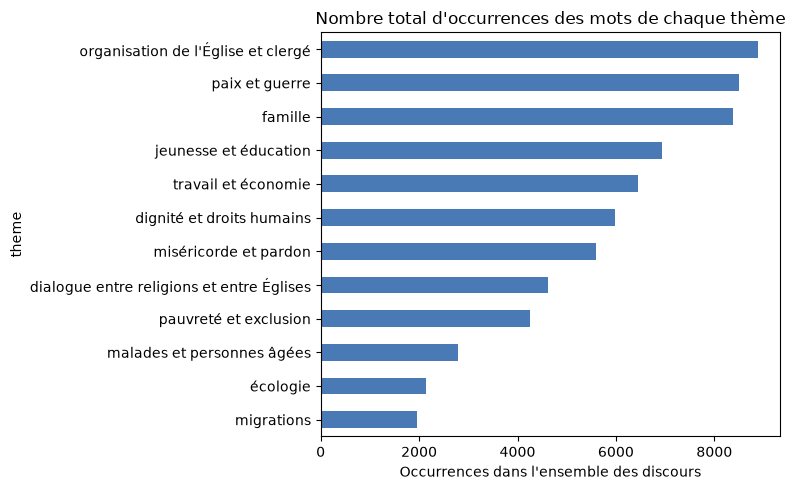

In [5]:
mots_par_theme = compter_mots_des_themes(textes)
mots_par_theme.to_csv(DOSSIER_RESULTATS / "mots_par_theme.csv", index=False, encoding="utf-8-sig")

total_par_theme = mots_par_theme.groupby("theme")["occurrences"].sum().sort_values()
total_par_theme.plot.barh(figsize=(8, 5), color="#4a7ab5")
plt.xlabel("Occurrences dans l'ensemble des discours")
plt.title("Nombre total d'occurrences des mots de chaque thème")
plt.tight_layout()
plt.show()

## 5. Statistiques par pays

Chaque discours est rattaché à un pays (règles dans `analyse_discours/pays.py`) :
« Avion » pour les conférences de presse en vol, « Vatican / Rome » pour la grande majorité.

In [6]:
discours = preparer_discours(charger_discours())
nb_par_pays = pd.Series([d["pays"] for d in discours]).value_counts()
print(f"{len(discours)} discours, {len(nb_par_pays)} lieux (pays, Avion, Vatican / Rome)")
nb_par_pays.head(15)

1742 discours, 69 lieux (pays, Avion, Vatican / Rome)


Vatican / Rome    1279
Italie              63
Avion               56
Brésil              16
États-Unis          14
Pologne             12
Portugal            10
Mexique              9
Israël               8
Colombie             8
Pérou                8
Japon                8
Corée du Sud         7
France               7
Bolivie              7
Name: count, dtype: int64

### 5.1 Un thème en détail

Le thème étudié est fixé par la variable `THEME_CHOISI`. Le tableau est trié par
**occurrences pour 10 000 mots** : c'est l'indicateur à comparer entre pays, car il tient compte
de la quantité de texte (beaucoup plus de discours au Vatican qu'en Albanie).

In [7]:
THEME_CHOISI = "migrations"
MIN_DISCOURS = 3   # on écarte les pays avec trop peu de discours

print(THEME_CHOISI, ":", stats_globales(THEMES[THEME_CHOISI], discours))
stats_theme = stats_par_pays(THEMES[THEME_CHOISI], discours)
stats_theme[stats_theme["discours"] >= MIN_DISCOURS].head(20)

migrations : {'discours': 1742, 'discours_avec_mot': 547, 'pct_discours': 31.4, 'occurrences': 1962, 'pour_10000_mots': 7.62}


,pays,discours,discours_avec_mot,pct_discours,occurrences,pour_10000_mots
0,Maroc,4,3,75.0,53,88.97
4,Turquie,5,3,60.0,13,31.28
6,Palestine,3,2,66.7,3,23.08
8,Chypre,4,3,75.0,15,17.85
9,Belgique,5,2,40.0,13,17.33
10,France,7,5,71.4,33,16.73
11,Thaïlande,6,4,66.7,14,16.14
12,Bulgarie,4,3,75.0,10,16.06
13,Grèce,6,5,83.3,18,14.55
14,Pologne,12,6,50.0,25,14.12


### 5.2 Tous les thèmes, tous les pays

Pour chaque thème et chaque pays, on calcule un **indice** :

indice = (fréquence du thème dans le pays) / (fréquence du thème dans tout le corpus)

- indice > 1 : le pape parle **plus** de ce thème dans ce pays qu'en moyenne
- indice < 1 : il en parle **moins**

Seuls les pays avec au moins `MIN_DISCOURS` discours sont gardés.

In [8]:
lignes = []
for theme, mots in THEMES.items():
    moyenne = stats_globales(mots, discours)["pour_10000_mots"]
    stats = stats_par_pays(mots, discours)
    stats = stats[stats["discours"] >= MIN_DISCOURS]
    for _, ligne in stats.iterrows():
        lignes.append({
            "theme": theme,
            "pays": ligne["pays"],
            "pour_10000_mots": ligne["pour_10000_mots"],
            "indice": round(ligne["pour_10000_mots"] / moyenne, 2),
        })

indices = pd.DataFrame(lignes)
indices.to_csv(DOSSIER_RESULTATS / "indices_themes_pays.csv", index=False, encoding="utf-8-sig")

# Tableau croisé : une ligne par thème, une colonne par pays
tableau_indices = indices.pivot(index="theme", columns="pays", values="indice")
tableau_indices

pays,Albanie,Arménie,Avion,Bahreïn,Bangladesh,Belgique,Bolivie,Bosnie-Herzégovine,Brésil,Bulgarie,...,Slovaquie,Soudan du Sud,Sri Lanka,Thaïlande,Timor oriental,Turquie,Vatican / Rome,Égypte,Équateur,États-Unis
theme,,,,,,,,,,,,,,,,,,,,,
dialogue entre religions et entre Églises,1.79,1.35,1.54,1.23,1.65,0.52,0.29,4.43,0.53,1.79,...,1.11,0.73,3.77,1.48,0.08,5.51,0.92,2.66,0.39,0.73
dignité et droits humains,2.36,1.25,0.97,1.39,0.77,1.09,2.18,0.63,0.63,0.28,...,2.43,0.99,1.09,1.74,0.61,2.79,0.96,1.61,0.60,2.66
famille,0.41,0.30,0.82,0.43,0.65,0.45,0.73,0.50,0.54,0.99,...,0.70,0.77,1.16,0.78,1.39,0.30,1.02,0.51,1.40,2.64
jeunesse et éducation,0.49,0.24,0.68,0.76,1.29,1.78,0.44,1.47,2.04,1.01,...,0.56,0.57,0.00,0.94,3.69,0.45,0.98,0.50,1.84,0.67
malades et personnes âgées,0.35,0.74,0.56,0.68,1.75,0.12,0.89,0.27,0.84,1.04,...,0.26,0.30,0.39,1.92,2.62,0.67,1.11,0.58,1.10,0.46
migrations,0.25,0.42,1.81,0.86,0.83,2.27,0.29,0.19,0.11,2.11,...,0.49,1.01,0.00,2.12,1.49,4.10,0.97,0.41,0.13,1.00
miséricorde et pardon,0.87,0.89,0.55,0.20,0.87,1.54,1.17,0.74,0.66,0.59,...,1.56,0.71,1.75,0.64,0.59,0.22,1.08,0.29,0.55,0.44
organisation de l'Église et clergé,1.04,0.00,0.84,0.34,1.80,0.58,0.84,1.40,1.04,1.35,...,0.55,0.89,0.12,0.97,1.11,0.14,1.07,0.45,0.92,0.53
paix et guerre,1.03,3.07,1.15,2.57,0.96,1.09,0.77,2.49,0.14,1.07,...,0.80,3.62,4.09,0.42,1.07,4.01,0.88,3.11,0.06,1.14


### 5.3 Carte de chaleur des indices

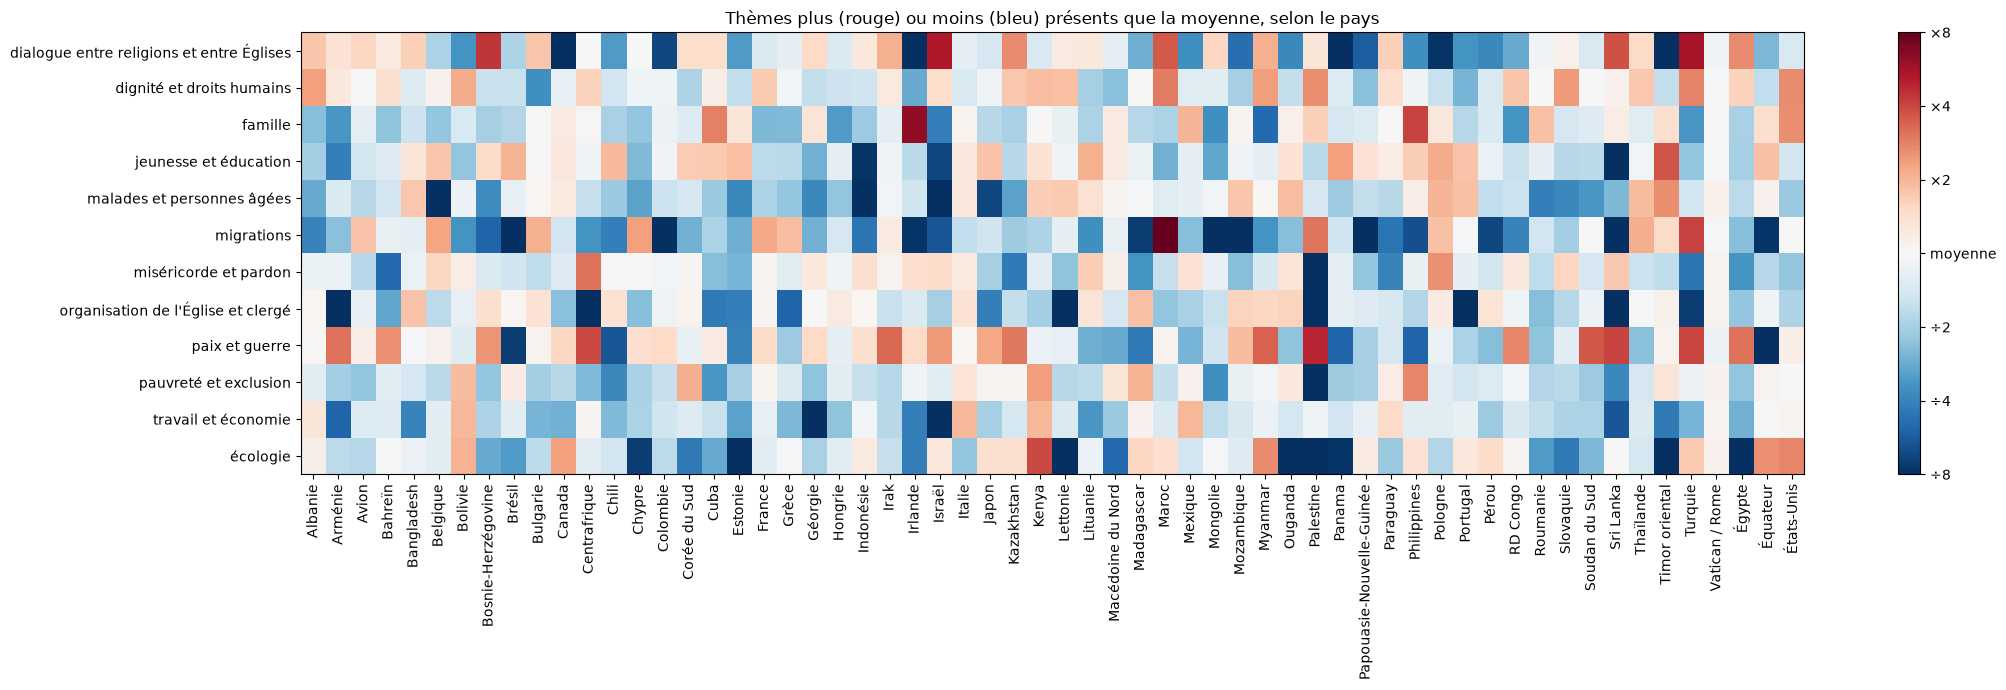

In [9]:
import numpy as np

# Échelle logarithmique : un indice de 2 et un indice de 0,5 sont à la même distance de 1
valeurs = np.log2(tableau_indices.clip(lower=0.125, upper=8).fillna(1).replace(0, 0.125))

fig, ax = plt.subplots(figsize=(22, 7))
image = ax.imshow(valeurs, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_xticks(range(len(tableau_indices.columns)))
ax.set_xticklabels(tableau_indices.columns, rotation=90)
ax.set_yticks(range(len(tableau_indices.index)))
ax.set_yticklabels(tableau_indices.index)
barre = fig.colorbar(image, ax=ax)
barre.set_ticks([-3, -2, -1, 0, 1, 2, 3])
barre.set_ticklabels(["÷8", "÷4", "÷2", "moyenne", "×2", "×4", "×8"])
ax.set_title("Thèmes plus (rouge) ou moins (bleu) présents que la moyenne, selon le pays")
plt.tight_layout()
plt.savefig(DOSSIER_RESULTATS / "carte_chaleur_themes_pays.png", dpi=150)
plt.show()

### 5.4 Pour chaque thème, les 5 pays où il est le plus surreprésenté

In [10]:
top5 = (indices.sort_values("indice", ascending=False)
               .groupby("theme")
               .head(5)
               .sort_values(["theme", "indice"], ascending=[True, False]))
top5

,theme,pays,pour_10000_mots,indice
300,dialogue entre religions et entre Églises,Turquie,98.65,5.51
301,dialogue entre religions et entre Églises,Israël,94.14,5.26
302,dialogue entre religions et entre Églises,Bosnie-Herzégovine,79.34,4.43
303,dialogue entre religions et entre Églises,Sri Lanka,67.43,3.77
304,dialogue entre religions et entre Églises,Maroc,63.79,3.56
360,dignité et droits humains,Maroc,68.83,2.96
361,dignité et droits humains,Turquie,64.97,2.79
362,dignité et droits humains,États-Unis,61.95,2.66
363,dignité et droits humains,Palestine,61.54,2.65
364,dignité et droits humains,Slovaquie,56.58,2.43


## 6. Les écarts sont-ils solides ?

L'indice de la partie 5 **décrit** les différences entre pays, mais ne dit pas si elles sont **fiables**.
Deux problèmes :

1. **Le hasard de l'échantillon.** Beaucoup de pays n'ont que 3 à 7 discours. Un seul discours très centré
   sur un thème (par exemple la rencontre avec les migrants à Rabat) suffit à faire exploser l'indice.
   → on mesure l'incertitude avec un **intervalle de confiance par bootstrap** (6.1).
2. **Les facteurs de confusion.** En voyage, le pape parle souvent aux autorités ; au Vatican, souvent au clergé.
   Un thème peut ressortir dans un pays à cause du **public** ou de **l'année**, pas du lieu.
   → on estime l'effet propre du lieu, à public et année égaux, avec une **régression binomiale négative** (6.2).

Le code est dans `analyse_discours/robustesse.py`.

In [ ]:
from robustesse import (bootstrap_tous_les_themes, intervalles_bootstrap, regression_theme,
                        resume_regressions, tableau_par_discours)
import numpy as np

### La démarche en un exemple

Avant les formules, le raisonnement complet est déroulé sur un cas réel :
le thème **paix et guerre** en **Irak** (voyage de mars 2021). La fonction `expliquer_demarche`
affiche chaque étape avec les vrais chiffres ; le thème et le pays sont ses deux paramètres.

In [ ]:
from robustesse import expliquer_demarche

expliquer_demarche(discours, theme="paix et guerre", pays="Irak")

### 6.1 Intervalle de confiance par bootstrap

**L'indice.** Pour un thème, on note pour chaque discours $i$ : $y_i$ le nombre d'emplois des mots du thème
et $n_i$ le nombre de mots du discours. Pour un pays $P$ :

$$\text{indice}_P = \frac{\sum_{i \in P} y_i \,/\, \sum_{i \in P} n_i}{f_0}
\qquad\text{avec}\qquad f_0 = \frac{\sum_{\text{tous}} y_i}{\sum_{\text{tous}} n_i}$$

**Le problème.** Cet indice est calculé sur un échantillon de discours : avec d'autres discours tout aussi
plausibles, il aurait été différent. Pour un rapport de sommes, il n'y a pas de formule simple de la variance.

**Le bootstrap.** On remplace la distribution inconnue des discours par celle qu'on observe, et on simule :

1. le pays a $n$ discours : on en tire $n$ au hasard **avec remise** (certains reviennent, d'autres manquent) ;
2. on recalcule l'indice sur cet échantillon fictif ;
3. on répète $B = 1\,000$ fois ;
4. l'intervalle de confiance à 95 % va du **quantile 2,5 %** au **quantile 97,5 %** des 1 000 indices
   (méthode des percentiles).

**Lecture.** Si l'intervalle est entièrement au-dessus de 1, le pape parle *significativement plus* du thème
dans ce pays ; entièrement en dessous, *significativement moins* ; s'il contient 1, l'écart n'est pas
significatif. En dessous de 3 discours, on ne calcule pas d'intervalle.

On traite $f_0$ comme fixe : calculé sur 1 742 discours, son incertitude est négligeable.

In [ ]:
ic_theme = intervalles_bootstrap(THEMES[THEME_CHOISI], discours)
ic_theme[ic_theme["discours"] >= MIN_DISCOURS].head(20)

Graphique : chaque point est l'indice d'un pays, le trait son intervalle à 95 %.
L'axe est logarithmique (×2 et ÷2 sont à la même distance de 1).
**Rouge** : significativement au-dessus de 1 ; **noir** : en dessous ; **gris** : non significatif.

In [ ]:
a_tracer = ic_theme[ic_theme["ic_bas"].notna()].sort_values("indice")
couleurs = a_tracer["conclusion"].map({"plus que la moyenne": "#C8102E",
                                       "moins que la moyenne": "#141414"}).fillna("#AAAAAA")
# bornes à 0,05 pour pouvoir utiliser une échelle logarithmique (un indice peut valoir 0)
indice = a_tracer["indice"].clip(lower=0.05)
bas = a_tracer["ic_bas"].clip(lower=0.05)
haut = a_tracer["ic_haut"].clip(lower=0.05)

fig, ax = plt.subplots(figsize=(8, 0.28 * len(a_tracer) + 1))
ax.hlines(range(len(a_tracer)), bas, haut, color=couleurs, linewidth=2)
ax.scatter(indice, range(len(a_tracer)), color=couleurs, zorder=3)
ax.axvline(1, color="#141414", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_yticks(range(len(a_tracer)))
ax.set_yticklabels(a_tracer["pays"] + " (" + a_tracer["discours"].astype(str) + ")")
ax.set_xlabel("indice (échelle log) — 1 = moyenne du corpus")
ax.set_title(f"« {THEME_CHOISI} » : indice et intervalle de confiance à 95 % (bootstrap)")
plt.tight_layout()
plt.show()

**Tous les thèmes d'un coup.** Combien d'écarts (thème, pays) résistent au bootstrap ?

In [ ]:
bootstrap = bootstrap_tous_les_themes(discours)
bootstrap.to_csv(DOSSIER_RESULTATS / "bootstrap_themes_pays.csv", index=False, encoding="utf-8-sig")

avec_ic = bootstrap[bootstrap["ic_bas"].notna()]
print(f"{len(avec_ic)} couples (thème, pays) avec au moins 3 discours")
print(avec_ic["conclusion"].value_counts().to_string())

# Les écarts significativement au-dessus de la moyenne
avec_ic[avec_ic["conclusion"] == "plus que la moyenne"].sort_values(["theme", "indice"], ascending=[True, False])

**Bilan du bootstrap.** La majorité des écarts visibles en partie 5 ne sont **pas** significatifs : l'indice
d'un pays avec 4 ou 5 discours est trop instable pour conclure. Il en reste une quarantaine, qui forment
le noyau solide de l'analyse par pays (par exemple *paix et guerre* au Moyen-Orient et en Afrique centrale).

Beaucoup d'écarts sont significativement **en dessous** de 1 : c'est logique, car un discours en voyage
est souvent centré sur un ou deux thèmes, et les autres y sont donc rares.

Limite : avec 3 à 5 discours, même le bootstrap est fragile (il ne peut pas inventer de la variété
absente de l'échantillon).

### 6.2 Régression binomiale négative

**Pourquoi.** Le bootstrap compare les pays sans rien contrôler. La régression estime l'effet de chaque variable
**à autres variables égales** : la région, le public et l'année en même temps.

**Le modèle.** Pour chaque discours $i$ :

$$y_i \sim \text{BinomialeNégative}(\mu_i, \alpha)
\qquad
\log \mu_i = \underbrace{\log n_i}_{\text{offset}} + \beta_0 + \beta_{\text{région}(i)} + \beta_{\text{public}(i)} + \beta_{\text{année}(i)}$$

- **Une loi de comptage** : $y_i$ est un entier positif (0, 1, 2…), une régression linéaire n'est pas adaptée.
- **Binomiale négative plutôt que Poisson** : la loi de Poisson impose variance = moyenne. Ici, beaucoup de
  discours ont 0 occurrence et quelques-uns en ont des dizaines : la variance est bien plus grande que la
  moyenne (**surdispersion**, vérifiée ci-dessous). La binomiale négative ajoute un paramètre $\alpha$ :
  $\text{Var}(y_i) = \mu_i + \alpha\,\mu_i^2$. Avec Poisson, les écarts-types seraient trop petits et l'on
  trouverait du « significatif » à tort.
- **L'offset** $\log n_i$ (coefficient fixé à 1) : $\mu_i = n_i \times e^{\beta_0 + \beta_{\text{région}} + \dots}$.
  On modélise donc un **taux par mot**, comme l'indice : un discours deux fois plus long contient en
  moyenne deux fois plus de mots du thème.
- **Variables qualitatives** : chaque modalité devient une indicatrice 0/1, sauf une **référence**
  (Vatican / Rome pour la région, « fidèles et autres » pour le public, 2013 pour l'année).
  Chaque coefficient est un écart à cette référence.

**Variables.**
- *Région* : Vatican / Rome, Italie, Europe, Moyen-Orient et Caucase, Afrique, Asie et Océanie, Amériques
  (les pays sont regroupés pour avoir assez de discours par modalité).
- *Public* : repéré par des mots du titre (« évêques », « jeunes », « autorités », « œcuménique »…).
- *Année* : pour ne pas confondre un effet du lieu avec un effet de la date (écologie autour de *Laudato si'* en 2015).

Les discours dans l'avion et de lieu inconnu sont écartés (pas de région).

**Estimation.** Les $\beta$ et $\alpha$ sont estimés par **maximum de vraisemblance** (`statsmodels`).

In [ ]:
tableau = tableau_par_discours(discours)
print(f"{len(tableau)} discours dans la régression\n")
print(tableau["region"].value_counts().to_string(), "\n")
print(tableau["public"].value_counts().to_string())

**Vérification de la surdispersion** : pour une loi de Poisson, variance / moyenne vaudrait environ 1.

In [ ]:
comptages = tableau[list(THEMES)]
surdispersion = pd.DataFrame({"moyenne": comptages.mean().round(2),
                              "variance": comptages.var().round(1)})
surdispersion["variance / moyenne"] = (surdispersion["variance"] / surdispersion["moyenne"]).round(1)
surdispersion.sort_values("variance / moyenne", ascending=False)

**Interprétation d'un coefficient.** Le modèle est en logarithme, donc un coefficient agit de façon **multiplicative** :

$$\text{rapport de taux} = e^{\beta}
\qquad
\text{IC à 95 \%} = \left[e^{\hat\beta - 1{,}96\,\text{se}} \;;\; e^{\hat\beta + 1{,}96\,\text{se}}\right]$$

Un rapport de taux de 2 pour « région : Afrique » veut dire : *à public et année égaux, le pape emploie deux fois
plus les mots du thème par mot prononcé en Afrique qu'au Vatican*. 0,5 veut dire deux fois moins.
L'intervalle n'est pas symétrique autour de la valeur, à cause de l'exponentielle.

La **p-value** est celle du test de Wald de $H_0 : \beta = 0$ (rapport de taux = 1, aucun effet), fondé sur
$z = \hat\beta / \text{se}$. Étoiles : `*` p < 0,05, `**` p < 0,01, `***` p < 0,001.

In [ ]:
resultat, coefficients = regression_theme(THEME_CHOISI, tableau)
print(f"Thème : {THEME_CHOISI}  —  alpha (surdispersion) estimé : {resultat.params['alpha']:.2f}")
coefficients

In [ ]:
# Les mêmes coefficients en graphique (échelle logarithmique)
c = coefficients.iloc[::-1]
couleurs = np.where(c["p_value"] >= 0.05, "#AAAAAA", np.where(c["rapport_de_taux"] > 1, "#C8102E", "#141414"))

fig, ax = plt.subplots(figsize=(8, 5))
ax.hlines(range(len(c)), c["ic_bas"], c["ic_haut"], color=couleurs, linewidth=2)
ax.scatter(c["rapport_de_taux"], range(len(c)), color=couleurs, zorder=3)
ax.axvline(1, color="#141414", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_yticks(range(len(c)))
ax.set_yticklabels(c["variable"])
ax.set_xlabel("rapport de taux (échelle log) — référence : Vatican, fidèles, même année")
ax.set_title(f"« {THEME_CHOISI} » : régression binomiale négative")
plt.tight_layout()
plt.show()

In [ ]:
# Résultat complet de statsmodels, années comprises : print(resultat.summary())

# Tous les thèmes : une colonne par thème, rapport de taux suivi des étoiles
resume = resume_regressions(tableau)
resume.to_csv(DOSSIER_RESULTATS / "regressions_themes.csv", encoding="utf-8-sig")
resume

**Lecture du tableau.** Il se lit **par colonne** : un thème, et ce qui le fait monter (> 1) ou baisser (< 1)
par rapport à un discours au Vatican devant des fidèles, la même année. On ne s'appuie que sur les cases
avec `**` ou `***`.

**Ce qui résiste aux contrôles** (résultats obtenus sur le corpus actuel) :

- **Paix et guerre** : ×2,0 en Afrique et ×2,3 au Moyen-Orient (***), ×2,4 devant les autorités (***).
  C'est le résultat géographique le plus net : le pape parle de paix dans les zones de conflit.
- **Dialogue entre religions** : ×1,9 au Moyen-Orient (**), et surtout ×7,9 devant un public œcuménique ou
  interreligieux (***).
- **Migrations** : une fois le public contrôlé, **aucune région ne parle plus de migrations que le Vatican** ;
  les Amériques en parlent même moins (×0,35 ***). L'effet vient du public : ×1,7 devant les autorités (*).
  Les indices élevés de Malte ou du Maroc sur la carte tiennent à un ou deux discours.
- **Organisation de l'Église** : beaucoup moins présente en voyage (×0,4 à ×0,7 selon les régions), beaucoup plus
  devant le clergé (×3,4 ***).
- **Le public pèse souvent plus que le lieu** : ×3,5 pour *jeunesse et éducation* devant les jeunes,
  ×2,1 pour *écologie* devant les autorités, ×0,24 pour *écologie* devant le clergé.

**Indice + bootstrap ou régression ?**

| | Indice + bootstrap | Régression |
|---|---|---|
| Comparé à | la moyenne de **tout le corpus** | le **Vatican**, devant des fidèles |
| Niveau | un **pays** | une **région** (assez de discours) |
| Contrôles | aucun | public et année |
| Question | « ce pays est-il atypique ? » | « le lieu a-t-il un effet propre ? » |

**Limites.**
- Ce sont des **corrélations**, pas des causes : le programme d'un voyage est choisi en fonction du pays.
- Le **public est deviné à partir du titre** : 949 discours restent dans « fidèles et autres », catégorie fourre-tout.
- Il manque des variables (type de discours : homélie, salutation…).
- **Tests multiples** : 12 thèmes × 11 coefficients = 132 tests ; au seuil de 5 %, environ 6 peuvent être
  « significatifs » par hasard. D'où la règle : ne retenir que `**` et `***`.
- Les discours d'un même voyage ne sont pas indépendants : les écarts-types sont un peu optimistes
  (des écarts-types « clusterisés » par voyage corrigeraient ce point).

## 7. Évolution des thèmes au fil du pontificat

C'était une des questions de départ (`docs/ANALYSE_NLP.md`) : *comment évoluent écologie, pauvreté,
migrations et paix au cours du pontificat ?*

Même méthode que pour les pays, mais par année : pour chaque thème, le nombre de mots du thème
**pour 10 000 mots prononcés** dans l'année. On tient ainsi compte du fait que le nombre de discours
varie beaucoup d'une année à l'autre.

Deux années comptent peu de discours : **2020** (44 discours, Covid) et surtout **2025**
(16 discours, avant la mort du pape le 21 avril).

In [ ]:
# Une ligne par discours : année, nombre de mots, et nombre de mots de chaque thème
lignes = []
for d in discours:
    ligne = {"annee": int(d["date"][:4]), "nb_mots": d["nb_mots"]}
    for theme, mots in THEMES.items():
        ligne[theme] = sum(d["compte_mots"][m.lower()] for m in mots)
    lignes.append(ligne)
par_discours = pd.DataFrame(lignes)

# On additionne par année, puis on rapporte au nombre de mots de l'année
par_annee = par_discours.groupby("annee").sum()
frequence_par_annee = (10000 * par_annee[list(THEMES)].div(par_annee["nb_mots"], axis=0)).round(1)
frequence_par_annee.to_csv(DOSSIER_RESULTATS / "themes_par_annee.csv", encoding="utf-8-sig")

print("Nombre de discours par année :")
print(par_discours["annee"].value_counts().sort_index().to_string())
frequence_par_annee.T   # une ligne par thème, une colonne par année

In [ ]:
# Les thèmes qui bougent le plus, en graphique
THEMES_A_SUIVRE = ["paix et guerre", "miséricorde et pardon", "famille",
                   "malades et personnes âgées", "écologie", "migrations"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, theme in zip(axes.flat, THEMES_A_SUIVRE):
    ax.plot(frequence_par_annee.index, frequence_par_annee[theme], marker="o", color="#C8102E")
    # en pointillés : la moyenne du thème sur tout le pontificat
    moyenne = 10000 * par_annee[theme].sum() / par_annee["nb_mots"].sum()
    ax.axhline(moyenne, color="#141414", linestyle="--", linewidth=1)
    ax.set_title(theme)
    ax.set_ylim(bottom=0)
for ax in axes[1]:
    ax.set_xlabel("année")
for ax in axes[:, 0]:
    ax.set_ylabel("pour 10 000 mots")
fig.suptitle("Évolution des thèmes (pointillés : moyenne du pontificat)")
plt.tight_layout()
plt.savefig(DOSSIER_RESULTATS / "evolution_themes.png", dpi=150)
plt.show()

**Lecture.** Les pics correspondent à des événements précis du pontificat :

| Thème | Pic | Ce qui l'explique |
|---|---|---|
| miséricorde et pardon | **2016** (49 pour 10 000 mots, contre 20 d'habitude) | le **Jubilé de la miséricorde** (déc. 2015 – nov. 2016) |
| famille | **2015** (49, contre 30) | les deux **synodes sur la famille** (2014 et 2015) |
| malades et personnes âgées | **2020** (20, contre 10) | la **pandémie de Covid-19** |
| paix et guerre | **2022** (52, contre 33), puis reste haut | la **guerre en Ukraine** |
| écologie | monte de 3 (2013) à 10 (2015) puis 15 (2020) | l'encyclique ***Laudato si'*** (mai 2015) |
| migrations | double à partir de 2016 | la **crise migratoire** en Méditerranée |

À l'inverse, *organisation de l'Église et clergé* baisse régulièrement (40 en 2013, 24 en 2023).

Ces pics sont-ils plus que du hasard ? **Le même bootstrap** que pour les pays s'applique, en
regroupant les discours par année au lieu de les regrouper par pays.

In [ ]:
from robustesse import intervalles_bootstrap

THEME_TEMPS = "miséricorde et pardon"   # thème étudié au fil des années

for d in discours:
    d["annee"] = d["date"][:4]   # la clé de regroupement du bootstrap

ic_annees = intervalles_bootstrap(THEMES[THEME_TEMPS], discours, cle="annee")
ic_annees.sort_values("annee", ignore_index=True)

**Lecture.** Pour *miséricorde et pardon*, l'indice de 2016 vaut 2,26 avec un intervalle [1,62 – 3,01], entièrement au-dessus de 1 :
le pic du Jubilé n'est pas un accident lié à quelques discours. Le même test s'applique à
*paix et guerre* en 2022, aux *malades* en 2020, etc.

**Limite.** Comme pour les pays, ce sont des corrélations : la composition des discours change aussi
d'une année à l'autre (plus ou moins de voyages, d'audiences, de publics différents). La régression de la
partie 6.2 contrôle déjà l'année ; contrôler inversement le lieu et le public isolerait l'effet propre
du temps.

## 8. Globe interactif

Cette cellule crée la page `analyse_discours/resultats/globe.html` (code dans `analyse_discours/globe.py`)
et l'ouvre dans le navigateur par défaut :

- le globe tourne par cliquer-glisser et se zoome à la molette ou avec les boutons + / − ;
- **pays** : onglets « Colorer par » — nombre de discours, nombre de voyages, ou indice d'un thème ;
- **fiche thème** (onglet Thème) : pays significativement au-dessus de la moyenne avec leur intervalle,
  et effets significatifs du lieu et du public estimés par la régression (partie 6.2) ;
- **fiche pays / ville** : un encadré explique en toutes lettres si l'écart du thème choisi est
  **vraiment significatif** ou non (bootstrap, partie 6.1) ; thèmes en jaune s'ils sont significatifs
  (en pointillés sinon), tableau des indices avec leur intervalle, effets significatifs de la région ;
- **villes** (table dans `analyse_discours/villes.py`) : carré = Rome, point noir = capitale, blanc = autre ville ;
- **voyages en avion** : un trait par voyage (Rome → étapes → Rome), un menu pour en choisir un,
  et un bouton pour les conférences de presse données dans l'avion.

Les anciennes fenêtres (`chercher_mot.py`, `explorer_discours.py`) sont conservées pour
montrer le cheminement.

In [11]:
from globe import creer_globe

OUVRIR_GLOBE = True   # True : la carte s'ouvre dans le navigateur ; False : page créée sans l'ouvrir

chemin_globe = creer_globe(discours, ouvrir=OUVRIR_GLOBE)
print("Globe enregistré :", chemin_globe.resolve().as_uri())

## 9. Conclusion

**De quoi parle le pape François, et cela dépend-il du lieu ?**

1. **Il voyage loin des seules capitales, mais pas tant que ça.** Hors Rome et Italie, environ
   **65 % des discours** dont on connaît la ville sont prononcés dans une capitale
   (59 capitales sur 111 villes visitées). Les grandes exceptions sont les villes des JMJ
   (Rio de Janeiro, Cracovie), de grandes métropoles (Philadelphie, New York, Istanbul),
   des sanctuaires (Fátima) ou des lieux symboliques (Lesbos, Ciudad Juárez).

2. **La plupart des écarts entre pays ne sont pas solides.** Avec 3 à 7 discours par pays, un seul
   discours peut faire exploser un indice : sur 708 couples (thème, pays), seuls **41** sont
   significativement au-dessus de la moyenne d'après le bootstrap.

3. **Ce qui résiste : la paix et le dialogue là où il y a des conflits.** À public et année égaux,
   le pape parle deux fois plus de paix et de guerre en **Afrique** (×2,0) et au **Moyen-Orient** (×2,3),
   et presque deux fois plus de dialogue entre religions au Moyen-Orient (×1,9).

4. **Le public compte souvent plus que le lieu.** Les migrations, par exemple, ne dépendent pas de la
   région une fois le public contrôlé : ce sont les discours aux **autorités** qui en parlent le plus.
   Devant le clergé, il parle d'Église (×3,4) ; devant les jeunes, d'éducation (×3,5) ;
   devant un public œcuménique, de dialogue (×7,9).

5. **Le calendrier pèse aussi.** Les thèmes suivent les grands moments du pontificat : Jubilé de la
   miséricorde (2016), synodes sur la famille (2015), Covid (2020), guerre en Ukraine (2022).

**En une phrase :** le pape adapte d'abord son discours **à son auditoire et à l'actualité** ; le lieu
ne joue un rôle propre que pour la paix et le dialogue interreligieux, dans les régions en conflit.

## Limites à garder en tête

- Les en-têtes des fichiers (titre, salle, date) sont comptés avec le texte.
- Un mot-clé peut avoir plusieurs sens ; les listes des thèmes sont à relire.
- Beaucoup de pays n'ont que 3 à 7 discours : un seul discours peut changer le classement
  (d'où les intervalles de confiance de la partie 6.1).
- Une différence entre pays peut venir du public (évêques, jeunes, autorités) ou de l'année plutôt
  que du lieu (d'où la régression de la partie 6.2, qui reste une analyse de corrélations).
- L'évolution dans le temps mélange plusieurs effets : actualité, mais aussi composition des discours
  de l'année (plus ou moins de voyages, de publics différents). 2020 et 2025 ont très peu de discours.
- Seuls les discours (genre « speeches » de vatican.va) sont étudiés : ni les homélies, ni les audiences
  générales, ni les encycliques.